<a href="https://colab.research.google.com/github/prudhvi-odela/AI4BIOMED26/blob/main/S2_FRMD7_STUDENT_CPY.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [35]:
!mkdir -p spatial


In [36]:
!ls -lh
!ls -lh spatial/


total 26M
drwxr-xr-x 1 root root 4.0K Oct 26 22:18 sample_data
drwxr-xr-x 3 root root 4.0K Oct 29 07:07 spatial
-rw-r--r-- 1 root root  26M Oct 29 07:07 Visium_FFPE_Human_Ovarian_Cancer_filtered_feature_bc_matrix.h5
total 16M
-rw-r--r-- 1 root root  1.8M Oct 29 07:05 aligned_fiducials.jpg
-rw-r--r-- 1 root root  1.8M Oct 29 07:05 detected_tissue_image.jpg
-rw-r--r-- 1 root root   165 Oct 29 07:05 scalefactors_json.json
-rw-r--r-- 1 root root   11M Oct 29 07:05 tissue_hires_image.png
-rw-r--r-- 1 root root 1021K Oct 29 07:05 tissue_lowres_image.png
-rw-r--r-- 1 root root  183K Oct 29 07:05 tissue_positions_list.csv


In [37]:
#dependency

In [38]:
# Install spatial transcriptomics packages (including scikit-misc for highly variable gene selection)
!pip install scanpy squidpy plotly anndata h5py leidenalg scikit-misc

# Imports
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.io as pio

# Configure Plotly to render inline in Colab
pio.renderers.default = "colab"
sc.settings.verbosity = 3

print("Dependencies installed and imported successfully!")

Dependencies installed and imported successfully!


block 1

In [39]:
# Load your uploaded local 10x Visium dataset with the exact filename
adata = sc.read_visium(
    path=".",
    count_file="Visium_FFPE_Human_Ovarian_Cancer_filtered_feature_bc_matrix.h5"
)
adata.var_names_make_unique()

print(adata)


reading Visium_FFPE_Human_Ovarian_Cancer_filtered_feature_bc_matrix.h5


/tmp/ipykernel_1692/2964063852.py:2: FutureWarning:

The function read_visium is deprecated and will be removed in the future. Use :func:`squidpy.read.visium` instead.



 (0:00:03)


/usr/local/lib/python3.13/dist-packages/scanpy/readwrite.py:248: UserWarning:

Variable names are not unique. To make them unique, call `.var_names_make_unique`.



AnnData object with n_obs × n_vars = 3455 × 17943
    obs: 'in_tissue', 'array_row', 'array_col'
    var: 'gene_ids', 'feature_types', 'genome'
    uns: 'spatial'
    obsm: 'spatial'
    layers: None (.X)


block 2 dep

block 2

In [40]:
# 1. Normalize gene counts so spots are comparable
sc.pp.normalize_total(adata, target_sum=1e4)

# 2. Log-transform data
sc.pp.log1p(adata)

# 3. Select top 2,000 highly variable genes using Seurat v3 flavor
sc.pp.highly_variable_genes(adata, flavor="seurat_v3", n_top_genes=2000)

# 4. Scale values so no single gene dominates (cap max at 10)
sc.pp.scale(adata, max_value=10)

normalizing counts per cell
    finished (0:00:11)
extracting highly variable genes


/tmp/ipykernel_1692/928628355.py:8: UserWarning:

`flavor='seurat_v3'` expects raw count data, but non-integers were found.



--> added
    'highly_variable', boolean vector (adata.var)
    'highly_variable_rank', float vector (adata.var)
    'means', float vector (adata.var)
    'variances', float vector (adata.var)
    'variances_norm', float vector (adata.var)


/usr/lib/python3.13/functools.py:934: UserWarning:

zero-centering a sparse array/matrix densifies it.



block 3

In [41]:
# 1. PCA: Compress thousands of genes into 50 principal components
sc.tl.pca(adata, n_comps=50)

# 2. Neighbors: Build graph of similar spots (k=10)
sc.pp.neighbors(adata, n_neighbors=10)

# 3. UMAP: Calculate 2D coordinates for visual projection
sc.tl.umap(adata)

# 4. Leiden: Group spots into community clusters (resolution 0.5)
sc.tl.leiden(adata, resolution=0.5)

computing PCA
    with n_comps=50
    finished (0:00:03)
computing neighbors
    using 'X_pca' with n_pcs = 50
    finished: added to `.uns['neighbors']`
    `.obsp['distances']`, distances for each pair of neighbors
    `.obsp['connectivities']`, weighted adjacency matrix (0:00:51)
computing UMAP
    finished: added
    'X_umap', UMAP coordinates (adata.obsm)
    'umap', UMAP parameters (adata.uns) (0:00:06)


/tmp/ipykernel_1692/1577834950.py:11: FutureWarning:

The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.



running Leiden clustering
    finished: found 9 clusters and added
    'leiden', the cluster labels (adata.obs, categorical) (0:00:01)


block4

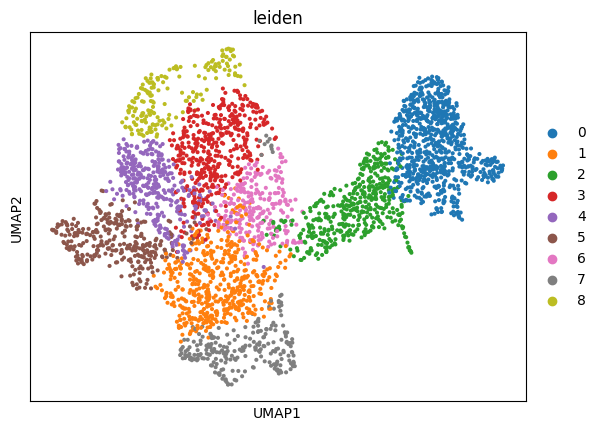

In [42]:
# Display clusters in 2D UMAP space
sc.pl.umap(adata, color="leiden")

block5


/tmp/ipykernel_1692/1638646511.py:2: FutureWarning:

The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.



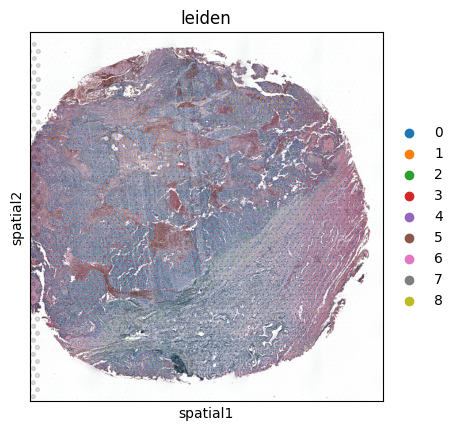

/tmp/ipykernel_1692/1638646511.py:6: FutureWarning:

The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.



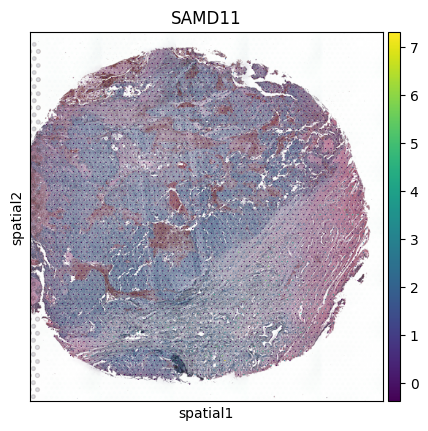

In [43]:
# 1. Plot actual tissue coordinates colored by Leiden cluster
sc.pl.spatial(adata, color="leiden", spot_size=30)

# 2. Plot tissue coordinates colored by gene expression (MT-CO1)
test_gene = "MT-CO1" if "MT-CO1" in adata.var_names else adata.var_names[0]
sc.pl.spatial(adata, color=test_gene, spot_size=30)

block6


INFO     Creating graph using `None` transform and `1` libraries.                                                  
Adding `adata.obsp['spatial_connectivities']`
       `adata.obsp['spatial_distances']`
       `adata.uns['spatial_neighbors']`


/tmp/ipykernel_1692/3379695602.py:2: FutureWarning:

Calling `spatial_neighbors` is deprecated and will be removed in squidpy v1.9.0. Use `spatial_neighbors_knn`, `spatial_neighbors_radius`, `spatial_neighbors_delaunay`, `spatial_neighbors_grid`, or `spatial_neighbors_from_builder` instead.



Calculating neighborhood enrichment using `1` core(s)


  0%|          | 0/1000 [00:00<?, ?/s]

Adding `adata.uns['leiden_nhood_enrichment']`
Finish (0:00:00)


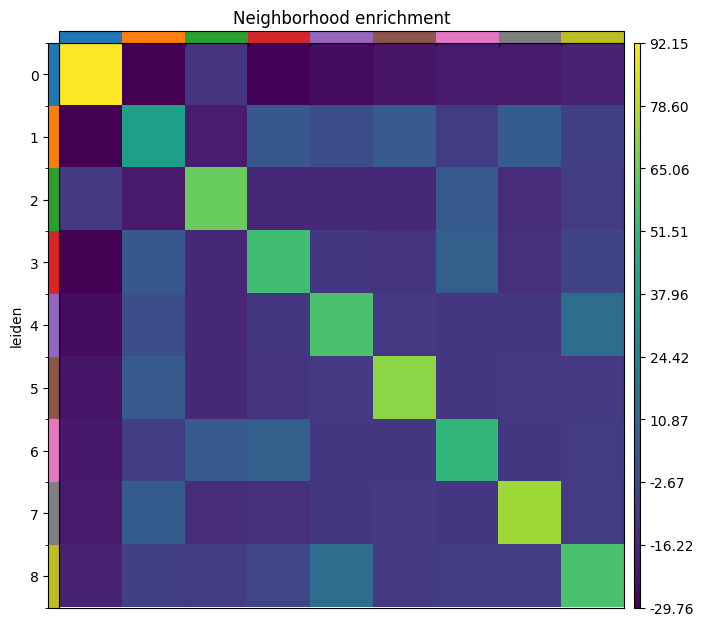

In [44]:
# 1. Compute physical spatial neighbors based on slide coordinates
sq.gr.spatial_neighbors(adata, coord_type="generic")

# 2. Calculate neighborhood enrichment between clusters
sq.gr.nhood_enrichment(adata, cluster_key="leiden")

# 3. Plot enrichment matrix heatmap
sq.pl.nhood_enrichment(adata, cluster_key="leiden")

block 7

In [45]:
def plot_interactive_gene(adata, gene_name="FRMD7"):
    coords = adata.obsm['spatial']

    if gene_name in adata.var_names:
        gene_exp = adata[:, gene_name].X
        if hasattr(gene_exp, "toarray"):
            gene_exp = gene_exp.toarray().flatten()
        else:
            gene_exp = np.array(gene_exp).flatten()
        color_val = gene_exp
        hover_label = gene_name
    else:
        print(f"Gene '{gene_name}' not found. Defaulting to Leiden cluster color.")
        color_val = adata.obs['leiden'].astype(str)
        hover_label = "cluster"

    df_plot = pd.DataFrame({
        'x': coords[:, 0],
        'y': coords[:, 1],
        'cluster': adata.obs['leiden'].astype(str),
        'expression': color_val
    })

    fig = px.scatter(
        df_plot,
        x='x',
        y='y',
        color='expression',
        hover_data=['cluster', 'expression'],
        title=f"Interactive Spatial Map: {gene_name}",
        color_continuous_scale="Viridis",
        width=750,
        height=750
    )

    # Reverse y-axis to match tissue microscopy orientation
    fig.update_yaxes(autorange="reversed")
    fig.show()

# Run interactive plot for Sulf1
plot_interactive_gene(adata, "FRMD7")

block 8

/tmp/ipykernel_1692/3303938951.py:5: FutureWarning:

The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.

/tmp/ipykernel_1692/3303938951.py:9: FutureWarning:

The function spatial is deprecated and will be removed in the future. Use :func:`squidpy.pl.spatial_scatter` instead.



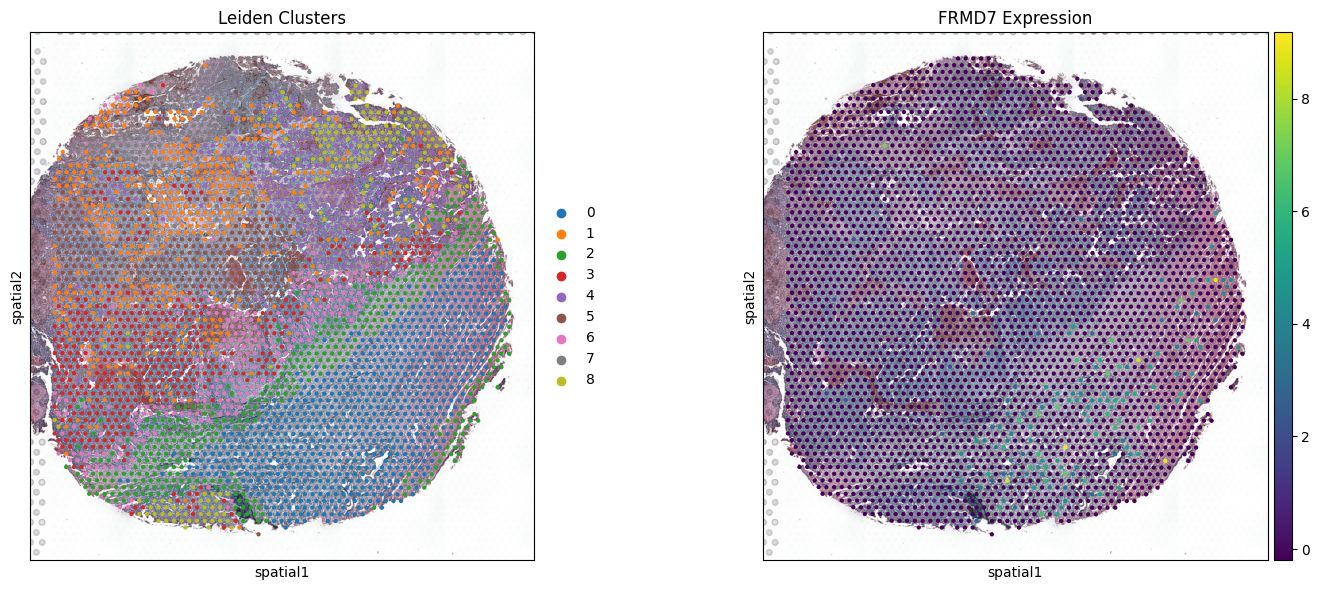

In [46]:


# Side-by-side comparison of Leiden clusters and Gene Expression
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Subplot 1: Clusters
sc.pl.spatial(adata, color="leiden", spot_size=80, ax=axes[0], show=False)
axes[0].set_title("Leiden Clusters")

# Subplot 2: Target Gene (Sulf1)
sc.pl.spatial(adata, color="FRMD7", spot_size=80, ax=axes[1], show=False)
axes[1].set_title("FRMD7 Expression")

plt.tight_layout()
plt.show()

In [47]:
import numpy as np

# Sum raw/normalized counts across all spots for each gene
gene_totals = np.asarray(adata.X.sum(axis=0)).flatten()
top_idx = np.argsort(gene_totals)[::-1]

# Display the top 10 most abundant genes
top_abundant_genes = adata.var_names[top_idx][:10].tolist()
print("Top 10 highest-expressed genes:", top_abundant_genes)

# Pick the most abundant one
target_gene = top_abundant_genes[0]
print(f"Selected gene: {target_gene}")

Top 10 highest-expressed genes: ['OAZ1', 'DDX5', 'CD63', 'HSPA8', 'CD160', 'PLD1', 'FRMD7', 'USP43', 'TMSB4X', 'RGN']
Selected gene: OAZ1
